[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/decoding.ipynb)

# Decoding timepoints

If features of some order carry information about what happens over time, one group of subjects' features at a timepoint should match the other group's features at the same timepoint. The decoders measure this match for each order. This notebook builds one decoding step by hand, then runs the four decoders on a small simulation.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.0 or
# later from PyPI, or, when that install fails, the GitHub branch named in FALLBACK.
import subprocess
import sys

if "google.colab" in sys.modules:
    PACKAGE = "timecorr"
    OTHERS = []                  # other packages installed with it
    FALLBACK = "master"                 # GitHub branch installed when PyPI does not have the release

    def pip_install(requirement):
        # returns pip's exit status and its output
        result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", requirement, *OTHERS],
                                capture_output=True, text=True)
        return result.returncode, result.stdout + result.stderr

    status, pypi_output = pip_install(f"{PACKAGE}>=0.3.0")
    if status == 0:
        print("Installed timecorr from PyPI.")
    else:
        status, github_output = pip_install(
            f"{PACKAGE} @ git+https://github.com/ContextLab/timecorr.git@{FALLBACK}")
        if status:
            print(pypi_output + github_output)
            raise RuntimeError("timecorr could not be installed; see pip's messages above.")
        print(f"Installed timecorr from the {FALLBACK} branch on GitHub (not from PyPI).")

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. Data

`tc.simulate_data` gives every subject the same correlations, which change between 5 events, while each subject's activity is its own draw. So the activity (order 0) is not shared across subjects, but the correlations (order 1) are. We use each subject's own correlations (`cfun=tc.autofc`).

In [3]:
data = tc.simulate_data(datagen='block', S=8, T=60, K=10, B=5, set_random_seed=0)
settings = {'cfun': tc.autofc, 'weights_function': tc.laplace_weights, 'weights_params': {'scale': 5}}
print(len(data), 'subjects, each', data[0].shape)

8 subjects, each (60, 10)


## 2. One decoding step by hand

`get_xval_assignments` splits the subjects into groups, and `folding_levels` computes one order's features for each group (averaged within the group). The **decoding matrix** correlates every timepoint of one group with every timepoint of the other, and `decoder` scores it; a timepoint is decoded correctly when its best match is the same timepoint.

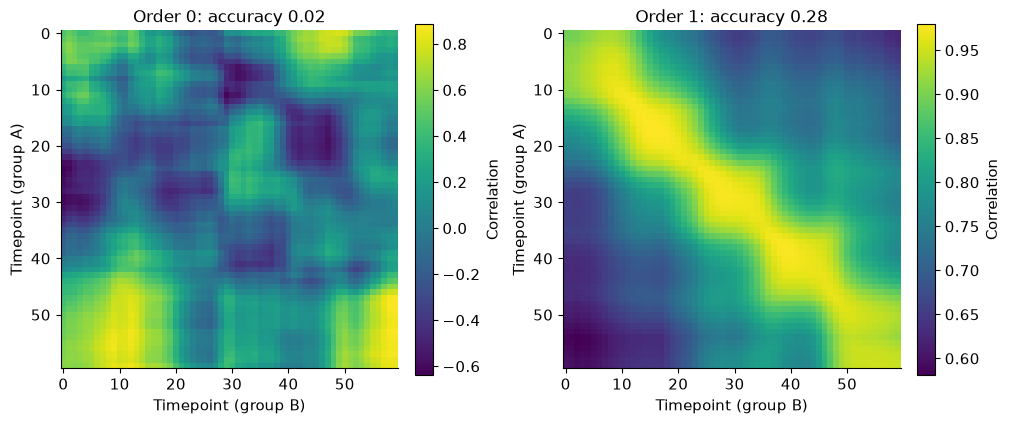

In [4]:
from scipy.spatial.distance import cdist
from timecorr.decoding import decoder, folding_levels, get_xval_assignments

np.random.seed(0)  # the split is random
group = get_xval_assignments(len(data), 2)
a = [d for d, g in zip(data, group) if g == 0]
b = [d for d, g in zip(data, group) if g == 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout='constrained')
for level, ax in enumerate(axes):
    feats_a, feats_b, _, _ = folding_levels(a, b, level=level, **settings)
    match = 1 - cdist(feats_a, feats_b, 'correlation')
    scores = decoder(match)
    im = ax.imshow(match, cmap='viridis')
    ax.set(title=f'Order {level}: accuracy {scores["accuracy"].iloc[0]:.2f}',
           xlabel='Timepoint (group B)', ylabel='Timepoint (group A)')
    fig.colorbar(im, ax=ax, label='Correlation', shrink=0.85)
plt.show()

Each panel has its own color scale. The order-1 matrix is brightest along the diagonal, so each timepoint best matches the same or nearby timepoints of the other group. Accuracy counts exact matches (chance is 1 / 60 here), `error` is the mean distance from the right timepoint as a fraction of the run, and `rank` is the fraction of timepoints that match no better than the right one (1 is best).

## 3. `timepoint_decoder`

`tc.timepoint_decoder` repeats this over folds (`nfolds`) for each requested order. Every order up to the highest is computed with the [two paths](higher_order.ipynb), using co-fluctuations on the feeding path.

In [5]:
np.random.seed(0)
results = tc.timepoint_decoder(data, level=[0, 1], nfolds=2, **settings)
print(results.groupby('level')[['accuracy', 'error', 'rank']].mean().round(3))

       accuracy  error   rank
level                        
0         0.008  0.225  0.420
1         0.242  0.027  0.956


`combine` averages each group's correlations, and `rfun` then reduces each order (both groups jointly), which keeps higher orders small. Here order 2 is decoded from the eigenvector centrality of each node, and with these data it decodes near chance (1 / 60).

In [6]:
np.random.seed(0)
deeper = tc.timepoint_decoder(data, level=2, nfolds=2, rfun='eigenvector_centrality',
                              combine=tc.corrmean_combine, **settings)
print(deeper.groupby('level')[['accuracy', 'error', 'rank']].mean().round(3))

       accuracy  error   rank
level                        
2         0.017   0.38  0.623


## 4. Mixing orders: `weighted_timepoint_decoder`

`tc.weighted_timepoint_decoder` mixes the orders' decoding matrices with weights that are learned on training subjects only and then used on held-out subjects. `optimize_weights` finds the weights and `weight_corrs` mixes the matrices; the columns `level_0`, `level_1` give the weights.

In [7]:
from timecorr.decoding import optimize_weights, weight_corrs

matrices = [1 - cdist(*folding_levels(a, b, level=k, **settings)[:2], 'correlation') for k in (0, 1)]
mu = optimize_weights(matrices)
print('weights of orders 0 and 1:', np.round(mu, 2))
print('mixed matrix:', weight_corrs(np.array(matrices), mu).shape)

np.random.seed(0)
weighted = tc.weighted_timepoint_decoder(data, level=1, nfolds=2, **settings)
print(weighted.groupby('level')[['accuracy', 'error', 'level_0', 'level_1']].mean().round(3))

weights of orders 0 and 1: [0. 1.]
mixed matrix: (60, 60)
       accuracy  error  level_0  level_1
level                                   
0         0.008  0.225      1.0      NaN
1         0.242  0.027      0.0      1.0


## 5. Your own lower-order features: `weighted_timepoint_decoder_ec`

`weighted_timepoint_decoder_ec` (in `timecorr.decoding`) takes the inputs of each order from you instead of computing the feeding path: `data[0]` is the data and `data[1]` the features that feed order 2. Here `data[1]` is the strength of each node in each subject's correlations; `folding_levels_ec` is its one-step helper.

In [8]:
from timecorr.decoding import folding_levels_ec, weighted_timepoint_decoder_ec

strength = tc.timecorr(data, rfun='strength', **settings)
feats_a, feats_b = folding_levels_ec([s for s, g in zip(strength, group) if g == 0],
                                     [s for s, g in zip(strength, group) if g == 1], level=1, **settings)[:2]
print('order-2 features of each group:', feats_a.shape, feats_b.shape)

np.random.seed(0)
ec = weighted_timepoint_decoder_ec([data, strength], level=2, nfolds=2, **settings)
print(ec.groupby('level')[['accuracy', 'error']].mean().round(3))

order-2 features of each group: (60, 55) (60, 55)
       accuracy  error
level                 
0         0.008  0.225
1         0.242  0.027
2         0.242  0.027


## 6. `pca_decoder`

`pca_decoder` (in `timecorr.decoding`) fits PCA to all subjects together. For each `d` up to `dims`, it smooths each group's first `d` components with the kernel and decodes from them. Here the subjects share no activity (section 1), so the components decode near chance.

In [9]:
from timecorr.decoding import pca_decoder

np.random.seed(0)
pca = pca_decoder(data, nfolds=2, dims=5, **settings)
print(pca.groupby('dims')[['accuracy', 'error']].mean().round(3))

      accuracy  error
dims                 
1        0.025  0.410
2        0.025  0.438
3        0.008  0.400
4        0.025  0.406
5        0.008  0.287


## 7. Events

All four decoders accept `events` (see the [events tutorial](events.ipynb)). For the correlation decoders the events restrict the kernel at orders 1 and up, and order 0 is unchanged. Resolving the events does not draw from NumPy's random state, so with the same seed the folds are the same with and without them.

In [10]:
np.random.seed(0)
with_events = tc.timepoint_decoder(data, level=[0, 1], nfolds=2, events=[12, 24, 36, 48], **settings)
print(with_events.groupby('level')[['accuracy', 'error']].mean().round(3))
level0 = results['level'] == 0
print('order-0 rows unchanged by events:',
      with_events[level0].reset_index(drop=True).equals(results[level0].reset_index(drop=True)))

       accuracy  error
level                 
0         0.008  0.225
1         0.075  0.076
order-0 rows unchanged by events: True


Order-1 accuracy falls with the events. To see why, we match the two groups of section 2 by hand at order 1 and also count matches that land in the right event.

In [11]:
event = np.arange(60) // 12  # 5 events of 12 timepoints
for name, ev in [('without events', None), ('with events', [12, 24, 36, 48])]:
    kw = dict(cfun=tc.autofc, combine=tc.mean_combine, events=ev,
              weights_function=tc.laplace_weights, weights_params={'scale': 5})
    best = (1 - cdist(tc.timecorr(a, **kw), tc.timecorr(b, **kw), 'correlation')).argmax(1)
    print(f'{name:15s} right timepoint {np.mean(best == np.arange(60)):.3f}, '
          f'right event {np.mean(event[best] == event):.3f}')
print('1 / 12 =', round(1 / 12, 3))

without events  right timepoint 0.283, right event 0.967
with events     right timepoint 0.083, right event 1.000
1 / 12 = 0.083


The true correlations do not change within an event, so with the events every match lands in the right event, but the timepoint within it is found only at the chance level of 1 / 12. Without events, the kernel mixes in the neighboring events, and that mix marks each timepoint's position within its event.

The picture on this tutorial's card in the gallery: the order-1 decoding matrix.

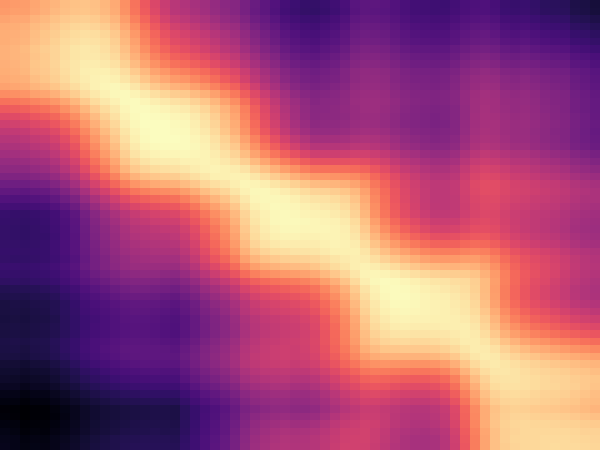

In [12]:
import io
from IPython.display import Image, display

fig = plt.figure(figsize=(4, 3), facecolor='white')
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(match, cmap='magma', aspect='auto', interpolation='nearest')
ax.set_axis_off()
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, facecolor='white')
plt.close(fig)
display(Image(buf.getvalue()))